# Benchmark: TrackNet V1 × YOLO

Este notebook compara os dois modelos no conjunto **`datasets/GSS_6/val`** sem comparar diretamente heatmaps com bounding boxes. Cada saída é primeiro reduzida a um ponto `(x, y)` na resolução original do frame:

- **TrackNet V1:** centroide ponderado da região ativa mais forte do heatmap;
- **YOLO:** centro da bounding box válida selecionada pelo critério de associação do benchmark;
- **Ground truth:** coordenadas `x y` dos arquivos de rótulo, quando `visibilidade > 0`.

Uma predição é **TP** quando seu centroide fica dentro do raio de tolerância do ground truth. Ausência de predição com bola visível é **FN**; predição com bola invisível é **FP**; ausência de ambos é **TN**. Uma predição fora do raio em um frame positivo produz **um FP e um FN**, como no pareamento de detecções: há uma detecção incorreta e um alvo não correspondido.

> Para garantir a mesma entrada temporal, os dois primeiros frames de cada clipe são excluídos dos dois modelos, pois o TrackNet V1 precisa de três frames consecutivos.


In [68]:
from dataclasses import dataclass
import matplotlib.pyplot as plt
from ultralytics import YOLO
from tqdm.auto import tqdm
from pathlib import Path
import numpy as np
import torch
import math
import csv
import sys
import cv2
import os


# Localiza a raiz mesmo se o notebook for aberto de benchmark/.
PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / 'datasets' / 'GSS_6' / 'val').exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Não foi possível localizar datasets/GSS_6/val.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from models.TracknetV1 import BallTrackerNet

# Caminhos
VAL_ROOT = PROJECT_ROOT / 'datasets' / 'GSS_6' / 'val'
TRACKNET_WEIGHTS = PROJECT_ROOT / 'exps' / 'gss6_finned_results' / 'model_best.pt'
YOLO_WEIGHTS = PROJECT_ROOT / 'used_model' / 'best.pt'
RESULTS_CSV = PROJECT_ROOT / 'benchmark' / 'tracknetv1_yolo_results.csv'

# Parâmetros comuns e de pós-processamento
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
TRACKNET_SIZE = (640, 360)  # largura, altura
TRACKNET_HEATMAP_THRESHOLD = 67 # Limite para considerar um pixel como parte da bola
TRACKNET_MIN_COMPONENT_AREA = 3 # Área mínima para considerar um componente como parte da bola
YOLO_BALL_CLASS_ID = 0 # ID da classe da bola no YOLO
YOLO_CONFIDENCE = 0.25 # Limite estrito de confiança para considerar uma detecção válida
YOLO_IOU = 0.45 # Limite de IOU para considerar uma detecção válida
YOLO_IMAGE_SIZE = 640
YOLO_BATCH_SIZE = 16
MATCH_RADIUS_PX = 30.0

# Use BENCHMARK_MAX_SAMPLES=20 para um teste rápido; 0 avalia todo o GSS_6 val.
_max_samples = int(os.getenv('BENCHMARK_MAX_SAMPLES', '0'))
MAX_SAMPLES = _max_samples or None

print(f'Raiz do projeto: {PROJECT_ROOT}')
print(f'Dispositivo: {DEVICE}')
print(f'Raio de correspondência: {MATCH_RADIUS_PX:.1f} px')
sample_text = MAX_SAMPLES if MAX_SAMPLES else 'todas'
print(f'Amostras: {sample_text}')


Raiz do projeto: d:\GoalballTracknetCustomVersion
Dispositivo: cuda
Raio de correspondência: 30.0 px
Amostras: todas


## 1. Amostras comuns e ground truth

A lista abaixo é criada diretamente de `GSS_6/val`. Cada amostra contém o frame atual, os dois frames anteriores exigidos pelo TrackNet e o rótulo pontual do frame atual.


In [14]:
@dataclass(frozen=True)
class Sample:
    sample_id: str
    current: Path
    previous: Path
    pre_previous: Path
    label: Path
    gt_x: float
    gt_y: float
    visibility: int

    @property
    def gt_visible(self):
        return self.visibility > 0


def read_label(label_path):
    parts = label_path.read_text(encoding='utf-8').strip().split()
    if len(parts) != 3:
        raise ValueError(f'Rótulo inválido em {label_path}: esperado x y visibilidade.')
    return float(parts[0]), float(parts[1]), int(parts[2])


def build_samples(val_root):
    frames_root = val_root / 'frames_out'
    labels_root = val_root / 'labels'
    samples = []

    for match_dir in sorted(p for p in frames_root.iterdir() if p.is_dir()):
        for clip_dir in sorted(p for p in match_dir.iterdir() if p.is_dir()):
            frames = sorted(
                p for p in clip_dir.iterdir()
                if p.suffix.lower() in {'.jpg', '.jpeg', '.png'}
            )
            for i in range(2, len(frames)):
                current = frames[i]
                relative = current.relative_to(frames_root)
                label = (labels_root / relative).with_suffix('.txt')
                if not label.exists():
                    raise FileNotFoundError(f'Rótulo não encontrado: {label}')
                gt_x, gt_y, visibility = read_label(label)
                samples.append(Sample(
                    sample_id=relative.as_posix(),
                    current=current,
                    previous=frames[i - 1],
                    pre_previous=frames[i - 2],
                    label=label,
                    gt_x=gt_x,
                    gt_y=gt_y,
                    visibility=visibility,
                ))
    return samples


samples = build_samples(VAL_ROOT)
if MAX_SAMPLES is not None:
    samples = samples[:MAX_SAMPLES]
if not samples:
    raise RuntimeError('Nenhuma amostra foi encontrada.')

visible_count = sum(s.gt_visible for s in samples)
print(f'Amostras comuns: {len(samples)}')
print(f'Bola visível: {visible_count} | bola não visível: {len(samples) - visible_count}')
print(f'Primeira amostra: {samples[0].sample_id}')


Amostras comuns: 5018
Bola visível: 3890 | bola não visível: 1128
Primeira amostra: partida01/clip003/img000003.jpg


## 2. Normalização das saídas para centroides

No TrackNet, o mapa de classes é limiarizado e separado em componentes conexos. A componente com maior soma de intensidade representa a região candidata, e seu centroide é ponderado pelos valores do heatmap. No YOLO, somente detecções válidas da classe `Ball` são consideradas. Quando o ground truth está disponível, a candidata mais próxima é usada; sem ele, a maior confiança é usada como fallback.


In [15]:
def tracknet_input(sample):
    images = []
    original_width = original_height = None
    for index, path in enumerate((sample.current, sample.previous, sample.pre_previous)):
        image = cv2.imread(str(path))
        if image is None:
            raise ValueError(f'Não foi possível ler {path}')
        if index == 0:
            original_height, original_width = image.shape[:2]
        images.append(cv2.resize(image, TRACKNET_SIZE))
    stacked = np.concatenate(images, axis=2).astype(np.float32) / 255.0
    return np.moveaxis(stacked, 2, 0), original_width, original_height


def tracknet_centroid(class_map, original_width, original_height):
    heatmap = np.asarray(class_map, dtype=np.uint8).reshape(
        TRACKNET_SIZE[1], TRACKNET_SIZE[0]
    )
    active = (heatmap >= TRACKNET_HEATMAP_THRESHOLD).astype(np.uint8)
    count, component_map, stats, _ = cv2.connectedComponentsWithStats(active, 8)

    candidates = [
        component_id for component_id in range(1, count)
        if stats[component_id, cv2.CC_STAT_AREA] >= TRACKNET_MIN_COMPONENT_AREA
    ]
    if not candidates:
        return None, None

    best_component = max(
        candidates,
        key=lambda component_id: float(heatmap[component_map == component_id].sum()),
    )
    mask = component_map == best_component
    ys, xs = np.nonzero(mask)
    weights = heatmap[mask].astype(np.float64)
    x_heatmap = float(np.average(xs, weights=weights))
    y_heatmap = float(np.average(ys, weights=weights))

    x = x_heatmap * original_width / TRACKNET_SIZE[0]
    y = y_heatmap * original_height / TRACKNET_SIZE[1]
    confidence = float(weights.mean() / 255.0)
    return (x, y), confidence


def yolo_centroid(result, ground_truth=None):
    boxes = result.boxes
    if boxes is None or len(boxes) == 0:
        return None, None

    classes = boxes.cls.detach().cpu().numpy().astype(int)
    confidences = boxes.conf.detach().cpu().numpy()
    candidates = np.flatnonzero(
        (classes == YOLO_BALL_CLASS_ID) & (confidences > YOLO_CONFIDENCE)
    )
    if len(candidates) == 0:
        return None, None

    coordinates = boxes.xyxy.detach().cpu().numpy()
    centers = (coordinates[:, :2] + coordinates[:, 2:]) / 2.0
    if ground_truth is None:
        best = int(candidates[np.argmax(confidences[candidates])])
    else:
        distances = np.linalg.norm(
            centers[candidates] - np.asarray(ground_truth), axis=1
        )
        best = int(candidates[np.argmin(distances)])
    x1, y1, x2, y2 = coordinates[best]
    point = (float((x1 + x2) / 2.0), float((y1 + y2) / 2.0))
    return point, float(confidences[best])


## 3. Inferência dos dois modelos

As células seguintes podem levar alguns minutos ao avaliar todas as amostras. O TrackNet usa os pesos treinados em `exps/gss6_finned_results/model_best.pt`; o YOLO usa `used_model/best.pt`.


In [58]:
if not TRACKNET_WEIGHTS.exists():
    raise FileNotFoundError(f'Pesos do TrackNet não encontrados: {TRACKNET_WEIGHTS}')

tracknet = BallTrackerNet().to(DEVICE)
checkpoint = torch.load(TRACKNET_WEIGHTS, map_location=DEVICE, weights_only=True)
if isinstance(checkpoint, dict) and 'state_dict' in checkpoint:
    checkpoint = checkpoint['state_dict']
tracknet.load_state_dict(checkpoint)
tracknet.eval()

tracknet_predictions = {}
sample_shapes = {}
with torch.inference_mode():
    for sample in tqdm(samples, desc='TrackNet V1'):
        input_array, original_width, original_height = tracknet_input(sample)
        sample_shapes[sample.sample_id] = (original_height, original_width)
        inputs = torch.from_numpy(input_array).unsqueeze(0).to(DEVICE)
        class_map = tracknet(inputs).argmax(dim=1)[0].detach().cpu().numpy()
        point, confidence = tracknet_centroid(
            class_map, original_width, original_height
        )
        tracknet_predictions[sample.sample_id] = {
            'point': point, 'confidence': confidence
        }

print(f'Predições TrackNet: {len(tracknet_predictions)}')


TrackNet V1: 100%|██████████| 5018/5018 [13:43<00:00,  6.09it/s]

Predições TrackNet: 5018


In [69]:
if not YOLO_WEIGHTS.exists():
    raise FileNotFoundError(f'Pesos do YOLO não encontrados: {YOLO_WEIGHTS}')

yolo = YOLO(str(YOLO_WEIGHTS))
if YOLO_BALL_CLASS_ID not in yolo.names:
    raise ValueError(
        f'Classe {YOLO_BALL_CLASS_ID} ausente no YOLO. Classes: {yolo.names}'
    )
print(f'Classe avaliada pelo YOLO: {yolo.names[YOLO_BALL_CLASS_ID]}')

yolo_predictions = {}
yolo_device = 0 if DEVICE == 'cuda' else 'cpu'
for start in tqdm(
    range(0, len(samples), YOLO_BATCH_SIZE),
    total=math.ceil(len(samples) / YOLO_BATCH_SIZE),
    desc='YOLO',
):
    batch_samples = samples[start:start + YOLO_BATCH_SIZE]
    batch_results = yolo.predict(
        source=[str(sample.current) for sample in batch_samples],
        classes=[YOLO_BALL_CLASS_ID],
        conf=YOLO_CONFIDENCE,
        iou=YOLO_IOU,
        imgsz=YOLO_IMAGE_SIZE,
        device=yolo_device,
        verbose=False,
    )
    if len(batch_results) != len(batch_samples):
        raise RuntimeError('O YOLO não retornou um resultado para cada frame.')
    for sample, result in zip(batch_samples, batch_results):
        ground_truth = (sample.gt_x, sample.gt_y) if sample.gt_visible else None
        point, confidence = yolo_centroid(result, ground_truth)
        yolo_predictions[sample.sample_id] = {
            'point': point, 'confidence': confidence
        }

print(f'Predições YOLO: {len(yolo_predictions)}')


Classe avaliada pelo YOLO: Ball


YOLO: 100%|██████████| 314/314 [06:05<00:00,  1.16s/it]

Predições YOLO: 5018


## 4. TP, TN, FP, FN e erro de posição

O erro é a distância Euclidiana entre o centroide predito e o ponto real, em pixels da imagem original. A média, mediana e percentil 95 usam frames com bola visível **e** algum ponto predito; falhas sem ponto permanecem representadas em FN e na cobertura. O erro normalizado é dividido pela diagonal de cada frame.


In [70]:
def safe_divide(numerator, denominator):
    return numerator / denominator if denominator else 0.0


def evaluate_model(model_name, predictions):
    counts = {'TP': 0, 'TN': 0, 'FP': 0, 'FN': 0}
    rows = []
    errors_px = []
    normalized_errors = []
    visible_with_prediction = 0

    for sample in samples:
        prediction = predictions[sample.sample_id]
        point = prediction['point']
        distance_px = None
        normalized_error = None

        if point is not None and sample.gt_visible:
            distance_px = float(np.hypot(point[0] - sample.gt_x, point[1] - sample.gt_y))
            height, width = sample_shapes[sample.sample_id]
            normalized_error = distance_px / float(np.hypot(width, height))
            errors_px.append(distance_px)
            normalized_errors.append(normalized_error)
            visible_with_prediction += 1

        if sample.gt_visible:
            if point is None:
                status = 'FN'
                counts['FN'] += 1
            elif distance_px <= MATCH_RADIUS_PX:
                status = 'TP'
                counts['TP'] += 1
            else:
                status = 'FP+FN'
                counts['FP'] += 1
                counts['FN'] += 1
        elif point is None:
            status = 'TN'
            counts['TN'] += 1
        else:
            status = 'FP'
            counts['FP'] += 1

        rows.append({
            'model': model_name,
            'sample_id': sample.sample_id,
            'visibility': sample.visibility,
            'gt_x': sample.gt_x,
            'gt_y': sample.gt_y,
            'pred_x': None if point is None else point[0],
            'pred_y': None if point is None else point[1],
            'confidence': prediction['confidence'],
            'distance_px': distance_px,
            'normalized_error': normalized_error,
            'status': status,
        })

    precision = safe_divide(counts['TP'], counts['TP'] + counts['FP'])
    recall = safe_divide(counts['TP'], counts['TP'] + counts['FN'])
    f1 = safe_divide(2 * precision * recall, precision + recall)
    metrics = {
        'model': model_name,
        **counts,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'visible_coverage': safe_divide(visible_with_prediction, visible_count),
        'mean_error_px': float(np.mean(errors_px)) if errors_px else float('nan'),
        'median_error_px': float(np.median(errors_px)) if errors_px else float('nan'),
        'p95_error_px': float(np.percentile(errors_px, 95)) if errors_px else float('nan'),
        'mean_normalized_error': (
            float(np.mean(normalized_errors)) if normalized_errors else float('nan')
        ),
        'errors_px': errors_px,
    }
    return metrics, rows


tracknet_metrics, tracknet_rows = evaluate_model('TrackNet V1', tracknet_predictions)
yolo_metrics, yolo_rows = evaluate_model('YOLO', yolo_predictions)
all_metrics = [tracknet_metrics, yolo_metrics]
all_rows = tracknet_rows + yolo_rows


In [71]:
columns = (
    f"{'Modelo':<12} {'TP':>6} {'TN':>6} {'FP':>6} {'FN':>6} "
    f"{'Precisão':>10} {'Recall':>10} {'F1':>10} {'Cobertura':>10} "
    f"{'Erro médio':>12} {'Mediana':>10} {'P95':>10} {'Erro/diag.':>11}"
)
print(columns)
print('-' * len(columns))
for m in all_metrics:
    print(
        f"{m['model']:<12} {m['TP']:>6} {m['TN']:>6} {m['FP']:>6} {m['FN']:>6} "
        f"{m['precision']:>10.4f} {m['recall']:>10.4f} {m['f1']:>10.4f} "
        f"{m['visible_coverage']:>9.2%} {m['mean_error_px']:>12.2f} "
        f"{m['median_error_px']:>10.2f} {m['p95_error_px']:>10.2f} "
        f"{m['mean_normalized_error']:>10.2%}"
    )
print(
    f'\nLeitura: métricas e cobertura maiores são melhores; erros menores são melhores. '
    f'Raio usado: {MATCH_RADIUS_PX:.1f} px.'
)


Modelo           TP     TN     FP     FN   Precisão     Recall         F1  Cobertura   Erro médio    Mediana        P95  Erro/diag.
-----------------------------------------------------------------------------------------------------------------------------------
TrackNet V1    3014   1086     62    876     0.9798     0.7748     0.8653    77.99%         4.73       1.81       5.98      0.21%
YOLO           2734   1038    164   1156     0.9434     0.7028     0.8055    72.19%        12.13       0.46       7.04      0.55%

Leitura: métricas e cobertura maiores são melhores; erros menores são melhores. Raio usado: 30.0 px.


### 4.1 Interpretação dos resultados de detecção

Os gráficos comparam as contagens de **TP**, **TN**, **FP** e **FN** dos modelos e resumem precisão, recall e F1-score. Uma correspondência é válida quando a bola está visível e a posição predita fica dentro do raio de tolerância definido no notebook.

- **Precisão:** proporção das detecções que foram consideradas válidas.
- **Recall:** proporção das bolas visíveis que foram localizadas corretamente.
- **F1-score:** equilíbrio entre precisão e recall.

Os valores exibidos nos gráficos e tabelas são gerados pela execução atual e devem ser usados diretamente na comparação.

> **Observação:** uma predição fora do raio de tolerância é contabilizada como falso positivo e falso negativo, representando uma detecção incorreta e um alvo não correspondido.

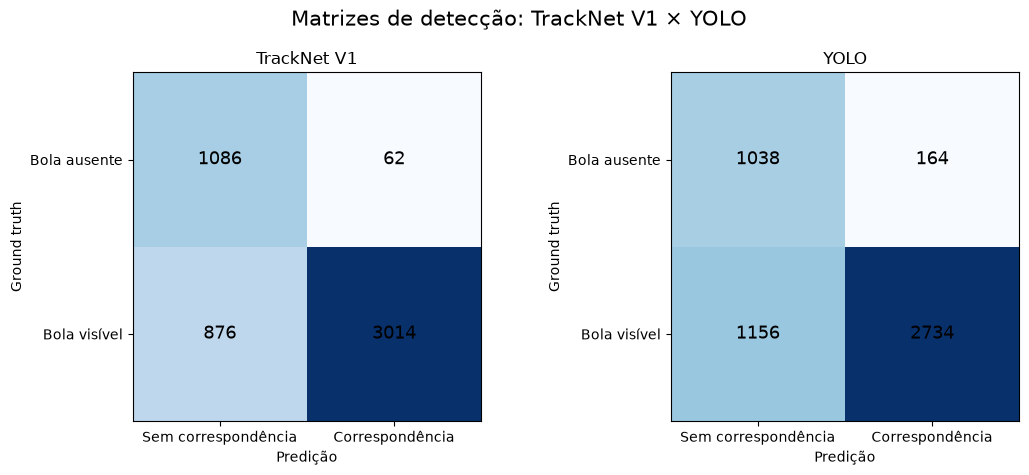

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
fig.suptitle('Matrizes de detecção: TrackNet V1 × YOLO', fontsize=15)

for ax, m in zip(axes, all_metrics):
    matrix = np.array([[m['TN'], m['FP']], [m['FN'], m['TP']]])
    ax.imshow(matrix, cmap='Blues')
    for row in range(2):
        for col in range(2):
            ax.text(col, row, str(matrix[row, col]), ha='center', va='center', fontsize=13)
    ax.set_xticks([0, 1], ['Sem correspondência', 'Correspondência'])
    ax.set_yticks([0, 1], ['Bola ausente', 'Bola visível'])
    ax.set_xlabel('Predição')
    ax.set_ylabel('Ground truth')
    ax.set_title(m['model'])

plt.tight_layout()
plt.show()


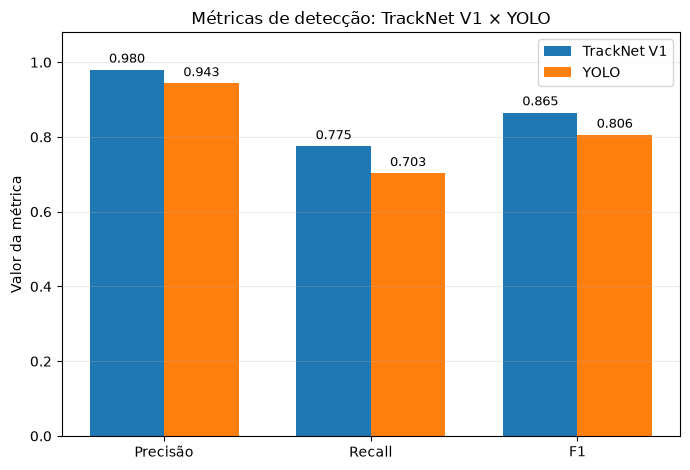

In [73]:
fig, ax = plt.subplots(figsize=(7, 4.8))
metric_names = ['precision', 'recall', 'f1']
x = np.arange(len(metric_names))
width = 0.36
for index, m in enumerate(all_metrics):
    values = [m[name] for name in metric_names]
    bars = ax.bar(
        x + (index - 0.5) * width, values, width, label=m['model']
    )
    ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=9)
ax.set_xticks(x, ['Precisão', 'Recall', 'F1'])
ax.set_ylabel('Valor da métrica')
ax.set_ylim(0, 1.08)
ax.set_title('Métricas de detecção: TrackNet V1 × YOLO')
ax.legend()
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()


### 4.2 Interpretação do erro de posição por frame

O gráfico apresenta o erro Euclidiano de localização em cada frame no qual a bola estava visível e o modelo produziu uma coordenada. O eixo horizontal representa a ordem das amostras e o eixo vertical representa o erro em pixels.

A escala logarítmica facilita a visualização conjunta de erros de diferentes magnitudes. A linha tracejada indica o raio de tolerância: círculos representam erros dentro desse limite e marcadores em `X` representam erros acima dele.

As estatísticas calculadas na execução, como média, mediana, percentil 95 e erro máximo, permitem comparar a precisão e a ocorrência de valores extremos entre os modelos.

> **Observação:** frames sem uma coordenada predita não aparecem neste gráfico, pois não possuem erro de posição calculável; essas falhas continuam representadas nas métricas de detecção.

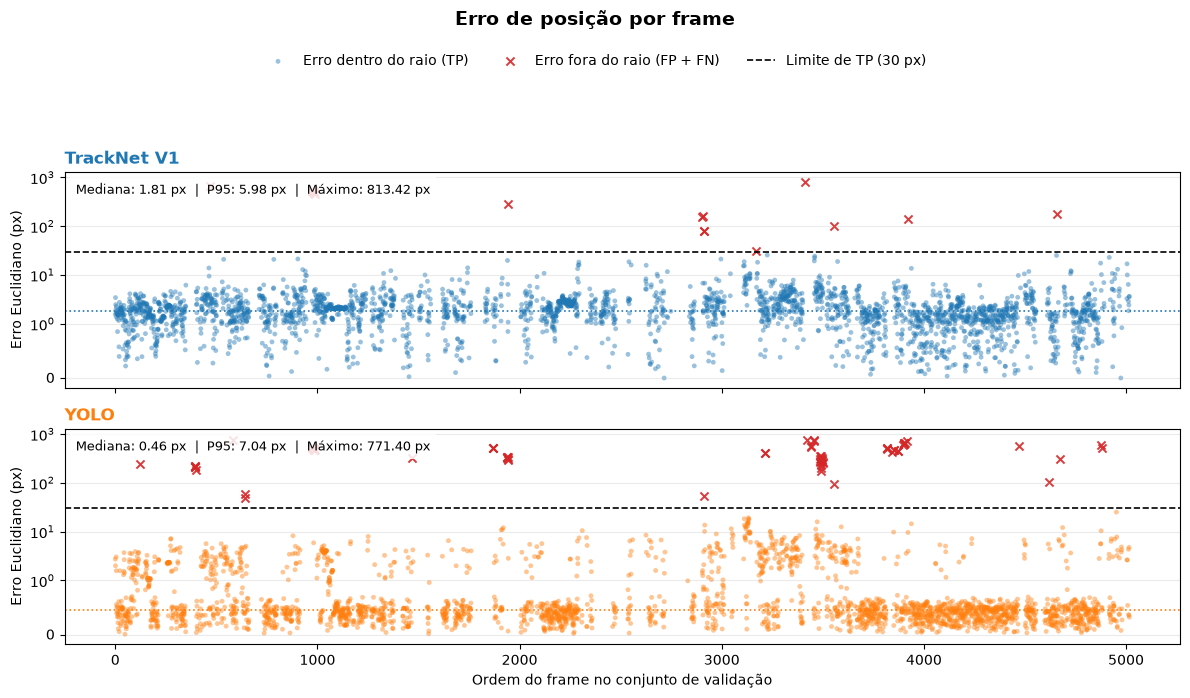

In [74]:
# Cada ponto representa o erro de uma predição em um frame com bola visível.
# Os painéis separados evitam a sobreposição dos modelos, e a escala simétrica
# logarítmica mantém legíveis tanto os erros pequenos quanto os outliers.
sample_position = {sample.sample_id: index for index, sample in enumerate(samples)}
model_colors = {'TrackNet V1': 'tab:blue', 'YOLO': 'tab:orange'}

fig, axes = plt.subplots(
    len(all_metrics), 1, figsize=(12, 7), sharex=True, sharey=True
)
axes = np.atleast_1d(axes)

for ax, m in zip(axes, all_metrics):
    model_rows = [
        row for row in all_rows
        if row['model'] == m['model'] and row['distance_px'] is not None
    ]
    frame_positions = np.asarray(
        [sample_position[row['sample_id']] for row in model_rows]
    )
    errors = np.asarray([row['distance_px'] for row in model_rows])
    within_radius = errors <= MATCH_RADIUS_PX
    outside_radius = ~within_radius
    model_color = model_colors.get(m['model'], 'tab:blue')

    ax.scatter(
        frame_positions[within_radius], errors[within_radius],
        s=12, alpha=0.45, color=model_color, edgecolors='none',
        label='Erro dentro do raio (TP)',
    )
    ax.scatter(
        frame_positions[outside_radius], errors[outside_radius],
        s=34, alpha=0.9, color='tab:red', marker='x', linewidths=1.4,
        label='Erro fora do raio (FP + FN)',
    )
    ax.axhline(
        MATCH_RADIUS_PX, color='black', linestyle='--', linewidth=1.2,
        label=f'Limite de TP ({MATCH_RADIUS_PX:.0f} px)',
    )
    ax.axhline(
        m['median_error_px'], color=model_color, linestyle=':', linewidth=1.2,
    )

    maximum_error = float(errors.max()) if len(errors) else float('nan')
    summary = (
        f"Mediana: {m['median_error_px']:.2f} px  |  "
        f"P95: {m['p95_error_px']:.2f} px  |  Máximo: {maximum_error:.2f} px"
    )
    ax.text(
        0.01, 0.95, summary, transform=ax.transAxes, va='top', ha='left',
        fontsize=9, bbox=dict(facecolor='white', alpha=0.85, edgecolor='none'),
    )
    ax.set_title(m['model'], loc='left', color=model_color, fontweight='bold')
    ax.set_ylabel('Erro Euclidiano (px)')
    ax.set_yscale('symlog', linthresh=1.0)
    ax.grid(axis='y', which='both', alpha=0.25)

axes[-1].set_xlabel('Ordem do frame no conjunto de validação')
handles, labels = axes[0].get_legend_handles_labels()
fig.suptitle('Erro de posição por frame', fontsize=14, fontweight='bold', y=0.99)
fig.legend(
    handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.945),
    ncol=3, frameon=False,
)
plt.tight_layout(rect=[0, 0, 1, 0.86])
plt.show()


## 5. Conferência visual e exportação

A visualização prioriza frames em que os modelos discordam. O CSV final mantém uma linha por modelo e frame para permitir análises adicionais.


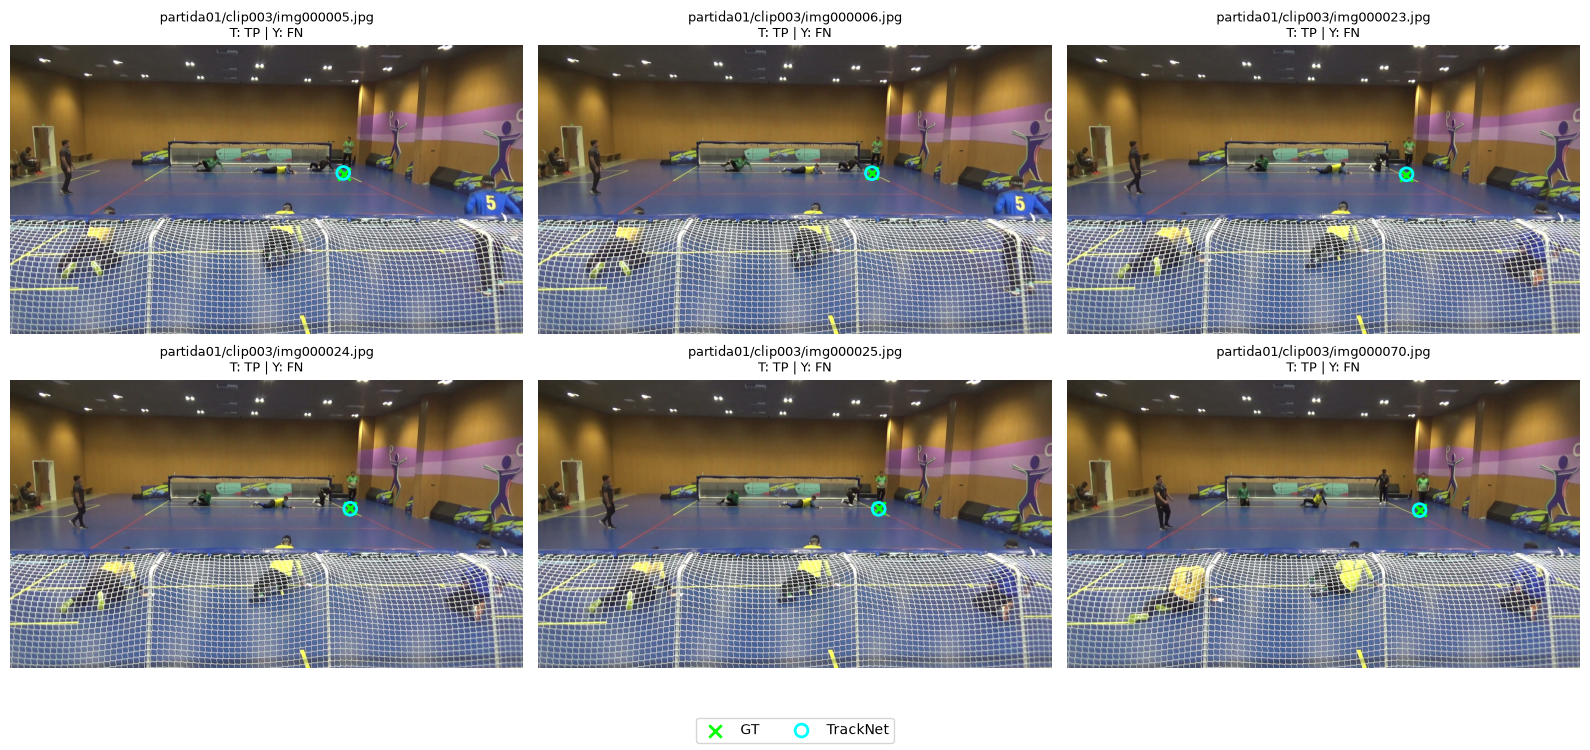

In [75]:
tracknet_by_id = {row['sample_id']: row for row in tracknet_rows}
yolo_by_id = {row['sample_id']: row for row in yolo_rows}
disagreements = [
    sample for sample in samples
    if tracknet_by_id[sample.sample_id]['status'] != yolo_by_id[sample.sample_id]['status']
]
examples = (disagreements or samples)[:6]

fig, axes = plt.subplots(2, 3, figsize=(16, 7.5))
for ax, sample in zip(axes.ravel(), examples):
    image = cv2.cvtColor(cv2.imread(str(sample.current)), cv2.COLOR_BGR2RGB)
    ax.imshow(image)
    if sample.gt_visible:
        ax.scatter(sample.gt_x, sample.gt_y, c='lime', marker='x', s=80, linewidths=2, label='GT')
    for model_name, predictions, color, marker in (
        ('TrackNet', tracknet_predictions, 'cyan', 'o'),
        ('YOLO', yolo_predictions, 'magenta', 's'),
    ):
        point = predictions[sample.sample_id]['point']
        if point is not None:
            ax.scatter(*point, facecolors='none', edgecolors=color, marker=marker, s=85, linewidths=2, label=model_name)
    ax.set_title(
        f"{sample.sample_id}\nT: {tracknet_by_id[sample.sample_id]['status']} | "
        f"Y: {yolo_by_id[sample.sample_id]['status']}",
        fontsize=9,
    )
    ax.axis('off')

for ax in axes.ravel()[len(examples):]:
    ax.axis('off')
handles, labels = axes.ravel()[0].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, loc='lower center', ncol=3)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()


In [76]:
fieldnames = [
    'model', 'sample_id', 'visibility', 'gt_x', 'gt_y', 'pred_x', 'pred_y',
    'confidence', 'distance_px', 'normalized_error', 'status',
]
with RESULTS_CSV.open('w', newline='', encoding='utf-8') as csv_file:
    writer = csv.DictWriter(csv_file, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(all_rows)

print(f'Resultados por frame salvos em: {RESULTS_CSV}')


Resultados por frame salvos em: d:\GoalballTracknetCustomVersion\benchmark\tracknetv1_yolo_results.csv
